# Moduli-Space Coordinate Pruning — a painstaking walkthrough

This notebook demonstrates **moduli-space coordinate pruning** end-to-end on the
small CNN from the quiver-construction visualization. We will:

1. Define the tiny network `Conv2d(1→2,3×3) → ReLU → Flatten(8) → Linear(8→4) → ReLU → Linear(4→3)`.
2. Train it on a small, *learnable* synthetic 4×4 image dataset (3 classes).
3. Walk step-by-step through the pruning pipeline in `moduli_space_pruning.py`:
   build the **quiver**, compute the per-edge **Eq. 5** representation `W_x^f`,
   analyze **coordinate statistics** over the dataset, map coordinates back to
   weights, **prune**, and compare against magnitude / random baselines.

It builds directly on the quiver construction shown here (edges = coordinates,
**#E = 46, #V = 3, moduli dim = 43**):

![quiver construction](education/project_visualizations/quiver_construction_walkthrough.png)

> **Note on the fixes.** Earlier, the pipeline was degenerate — every coordinate
> in a layer received the *same* value, and `prune()` silently did magnitude
> pruning. The core file now implements the genuine per-edge Eq. 5 contribution
> fractions and coordinate-driven pruning, which is what makes this walkthrough
> meaningful.


## How to use this notebook

**Audience.** You are continuing this research; you are strong in mathematics but may
be new to this specific paper, to neural-network pruning, and to this codebase. This
notebook is meant to be a **one-stop reference**: the math is defined from scratch, the
implementation is tied line-by-line to the theory, and the places where the code
*diverges* from the theory are called out explicitly so you don't build on a false
assumption.

**How it is organised.**
- **Part I — Mathematical foundations.** Quivers, representations, the gauge group, the
  moduli space, and the data representation $W_x^f$, with a fully worked by-hand example.
- **Bridge.** The source paper, a notation "Rosetta stone", the pruning literature, and a
  map of the codebase.
- **Part II — The walkthrough.** Train a tiny CNN and run the whole pipeline end-to-end,
  including an **executable demonstration of gauge invariance** (the theoretical selling
  point).
- **Part III — Rigor & research.** Multi-seed evaluation, fine-tuning, an honest list of
  **where the implementation diverges from the theory**, a **glossary**, and an **open
  research agenda**.

**Running it.**
- Kernel: a Python with `torch`, `numpy`, `matplotlib` (CPU is fine). If you re-run via
  `jupyter nbconvert --execute`, pass `--ExecutePreprocessor.kernel_name=python3`.
- Training is cached to `tinycnn_trained.pt`; delete that file to retrain.
- The three architecture/quiver/data-flow figures come from `notebook_viz.py`; running
  `python notebook_viz.py` regenerates the standalone PNGs and the checkpoint.


In [1]:
import sys, torch, numpy, matplotlib
print("python     ", sys.version.split()[0])
print("torch      ", torch.__version__)
print("numpy      ", numpy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.5
torch       2.12.0
numpy       2.1.3
matplotlib  3.10.0



# Part I — Mathematical foundations

The method rests on one exact statement (Armenta & Jodoin, 2020):

> A neural network **is** a representation of a quiver, and a forward pass induces a
> point in the **moduli space** of such representations.

Pruning then becomes: *find the moduli-space coordinates the data does not use, and
remove them.* The next cells define each italicised object precisely.



## I.1 Quivers

A **quiver** is a directed multigraph
$$ Q = (Q_0,\; Q_1,\; s,\; t), $$
where $Q_0$ is a finite set of **vertices**, $Q_1$ a finite set of **arrows**, and
$s,t : Q_1 \to Q_0$ send each arrow $\varepsilon$ to its **source** $s(\varepsilon)$ and
**target** $t(\varepsilon)$. A **path** is a sequence of arrows $\varepsilon_k\cdots
\varepsilon_1$ with $t(\varepsilon_i)=s(\varepsilon_{i+1})$; concatenation of paths makes
the $\mathbb{C}$-vector space on all paths into the **path algebra** $\mathbb{C}Q$.

**The network quiver.** For a feed-forward network, take
- $Q_0 = $ the **neurons** (for a conv layer, the **channels**), and
- $Q_1 = $ the **connections** carrying a trainable weight (one arrow per scalar weight
  in the faithful picture).

Architecture $\leftrightarrow$ quiver; the *weights* are extra data layered on top of
$Q$, which is the subject of the next section. In code this object is
`QuiverRepresentation(net)`, whose `.edges` are the arrows $Q_1$ and `.vertices` the
hidden vertices.



## I.2 Representations of a quiver — and why a network is one

A **representation** $W$ of $Q$ assigns
- a finite-dimensional vector space $V_v$ to each vertex $v$ (its **dimension vector** is
  $\mathbf d = (\dim V_v)_{v\in Q_0}$), and
- a linear map $W_\varepsilon : V_{s(\varepsilon)} \to V_{t(\varepsilon)}$ to each arrow.

A representation is **thin** if every $V_v$ is one-dimensional; then each $W_\varepsilon$
is just a scalar. The space of all representations with a fixed dimension vector is
$$ \mathrm{Rep}(Q,\mathbf d) \;=\; \bigoplus_{\varepsilon\in Q_1}
   \mathrm{Hom}(V_{s(\varepsilon)},V_{t(\varepsilon)}) \;\cong\; \mathbb{C}^{\#Q_1}
   \quad(\text{thin case}). $$

**The dictionary.** A neural network with weights $W$ is *exactly* a representation of
its network quiver: the weight on arrow $\varepsilon$ is the map $W_\varepsilon$. Hence

$$ \textbf{parameter space} \;=\; \mathrm{Rep}(Q,\mathbf d) \;\cong\; \mathbb{R}^{\#E}, $$

where $\#E=\#Q_1$ is the number of weights. This is the space `module.weight` lives in.
The architecture fixes $Q$ and $\mathbf d$; training moves a point around in
$\mathrm{Rep}(Q,\mathbf d)$.



## I.3 The forward pass, intrinsically

Fix an activation $f_v$ at each vertex (e.g. ReLU at hidden vertices, identity at the
output). For an input $x$, the network's activations are defined vertex-by-vertex
(Armenta–Jodoin, Def. 4.7):
$$ a(W,f)_v(x) \;=\; f_v\!\Big( \sum_{\alpha \in \zeta_v} W_\alpha\,
   a(W,f)_{s(\alpha)}(x) \Big), \qquad
   \zeta_v := \{\alpha\in Q_1 : t(\alpha)=v\}. $$

So $\zeta_v$ is the set of arrows **into** $v$, and the quantity inside $f_v$ is the
familiar **pre-activation** of neuron $v$. (Note: the paper's sum carries no bias term;
the implementation includes the bias — see Part III.) For a `Linear` layer with weight
$W$ (shape `out`$\times$`in`) and input activations $a$, the pre-activation of output
neuron $j$ is $\mathrm{preact}_j=\sum_i W_{j i}\,a_i$.



## I.4 Gauge symmetry: when are two networks "the same"?

Different weights can compute the **same function**. Two sources of this redundancy:

**(a) Rescaling (the ReLU gauge).** Because $\mathrm{ReLU}(t\,z)=t\,\mathrm{ReLU}(z)$ for
$t>0$, we may multiply every arrow *into* a hidden vertex $v$ by $t_v>0$ and every arrow
*out of* $v$ by $t_v^{-1}$ without changing the function:
$$ W^{\text{out}}\,\mathrm{ReLU}(W^{\text{in}} x) \;=\;
   (t_v^{-1}W^{\text{out}})\,\mathrm{ReLU}(t_v\,W^{\text{in}} x). $$

**(b) Permutation.** Relabelling the neurons within a layer permutes rows/columns and
leaves the function unchanged.

Algebraically these are the **change-of-basis** action of the **gauge group**
$$ \tilde G \;=\; \prod_{v\,\in\,\tilde V} \mathbb{C}^{*}
   \qquad(\text{positive reals }\mathbb{R}_{>0}\text{ for the ReLU/real case}), $$
one scalar per **hidden** vertex $\tilde V$ (input and output vertices are *framed* — fixed
by the data and the labels — so they carry no gauge freedom). The action is
$W_\varepsilon \mapsto t_{t(\varepsilon)}\, W_\varepsilon\, t_{s(\varepsilon)}^{-1}$.
Two representations in the same $\tilde G$-orbit are **isomorphic** and define the same
network function (on the data manifold).



## I.5 The moduli space and its dimension

The **moduli space** is the quotient that identifies isomorphic networks to a single
point:
$$ \mathcal M \;=\; \mathrm{Rep}(Q,\mathbf d) \,/\!/\, \tilde G . $$
(Formally a GIT quotient in the sense of Mumford/King; the "$/\!/$" keeps it a nice
variety by restricting to *semistable* points. We will not need the stability theory
here, but it is where the geometry lives.)

**Dimension.** Generically the orbits are free of dimension $\dim\tilde G$, so
$$ \boxed{\dim \mathcal M \;=\; \#E \;-\; \#\tilde V } $$
— the number of weights minus the number of **hidden** vertices, because each hidden
vertex contributes exactly one scalar of gauge freedom. This is the network's *intrinsic*
number of degrees of freedom: capacity, not parameter count.

> ⚠️ **Heads-up (detailed in Part III).** The code's `analyzer.moduli_dimension`
> subtracts the number of parametric **layers**, not the number of hidden **vertices**.
> For our CNN that is $46-3=43$ in code versus the paper's $46-6=40$. Keep the two
> numbers distinct in your head.



## I.6 The data representation $W_x^f$ — coordinates the data actually uses

A forward pass turns the weights *plus* an input $x$ into a new **thin** representation
$W_x^f$ — a point in the moduli space — defined arrow-by-arrow (Armenta–Jodoin, Sec. 6):
$$ \big(W_x^f\big)_\varepsilon \;=\;
   \frac{ W_\varepsilon\; a(W,f)_{s(\varepsilon)}(x) }
        { \displaystyle\sum_{\delta\,\in\,\zeta_{t(\varepsilon)}}
          W_\delta\; a(W,f)_{s(\delta)}(x) }
   \;=\; \frac{ W_\varepsilon\, a_{s(\varepsilon)} }{ \mathrm{preact}_{t(\varepsilon)} }. $$
For a `Linear` layer this is the matrix $\;(W_x^f)_{j i} = W_{j i}\,a_i / \mathrm{preact}_j$:
the **fraction of output neuron $j$'s pre-activation contributed by input $i$**. By
construction each row sums to $1$.

**Why divide?** The normalization is the whole point. Under a gauge rescaling at hidden
vertex $v$ by $t_v>0$, both the numerator and the denominator pick up exactly the same
factor, so **$W_x^f$ is invariant**:
$$ W_x^f(t\cdot W) \;=\; W_x^f(W), \qquad
   W_x^f(\sigma\cdot W) \;=\; \sigma\!\cdot\! W_x^f(W)\ \ (\text{permutation }\sigma). $$
So $W_x^f$ is a genuine, *parameterization-independent* coordinate on the moduli space —
unlike a raw weight magnitude, which is not. We verify this numerically in Step 2½.

**Connection to capacity.** Summed along paths, these normalized coordinates are the
*basis paths* of Zheng et al. (2019); coordinate importance is thus tied to the
basis-path norm and, conjecturally, to generalization.



### A fully worked example (do this by hand first)

Network $2\to2\to1$ with ReLU on the hidden layer:
$$ W^{(1)}=\begin{pmatrix}1&2\\3&-1\end{pmatrix},\quad
   W^{(2)}=\begin{pmatrix}2&-1\end{pmatrix},\quad x=(1,1). $$
- Arrows: $\#E = 2\cdot 2 + 2\cdot 1 = 6$. Hidden vertices: $\#\tilde V = 2$. So
  $\dim\mathcal M = 6-2 = 4$.
- Pre-activations of the hidden layer: $\mathrm{preact}=W^{(1)}x=(3,2)$.
- First-layer coordinates $(W_x^f)_{j i}=W^{(1)}_{j i}x_i/\mathrm{preact}_j$ — each row
  should sum to $1$.

The code cell confirms it.


In [2]:
import numpy as np
W1 = np.array([[1.0, 2.0], [3.0, -1.0]])     # hidden(2) x input(2)
W2 = np.array([[2.0, -1.0]])                  # output(1) x hidden(2)
x  = np.array([1.0, 1.0])

E      = W1.size + W2.size                     # number of arrows / weights
Vhidden = 2                                    # hidden vertices
preact = W1 @ x                                # pre-activation at the hidden layer
M1 = (W1 * x[None, :]) / preact[:, None]       # (W_x^f) on the first layer

print(f"#E = {E},  #V_hidden = {Vhidden},  moduli dim = {E - Vhidden}")
print("hidden pre-activations:", preact)
print("first-layer W_x^f =\n", np.round(M1, 4))
print("row sums (should be 1):", M1.sum(axis=1))

#E = 6,  #V_hidden = 2,  moduli dim = 4
hidden pre-activations: [3. 2.]
first-layer W_x^f =
 [[ 0.3333  0.6667]
 [ 1.5    -0.5   ]]
row sums (should be 1): [1. 1.]



## The source paper and a notation "Rosetta stone"

> **M. Armenta and P.-M. Jodoin (2020/2021).** *The Representation Theory of Neural
> Networks.* arXiv:**2007.12213**; *Machine Learning* (2021).

Read it alongside this notebook. The data representation appears in **Section 6** (the
repo and this notebook loosely call it "Eq. 5"); the change-of-basis group is Def. 3.9 /
4.12; the activation recursion is Def. 4.7.

| Paper (Armenta–Jodoin) | Code (`moduli_space_pruning.py`) | This notebook |
|---|---|---|
| network quiver $Q$ | `QuiverRepresentation` | `quiver` |
| arrow $\varepsilon$, weight $W_\varepsilon$ | edge `(idx, edge_info, layer)` | `quiver.edges` |
| representation $W\in\mathrm{Rep}(Q,\mathbf d)$ | `module.weight` | `net.fc1.weight`, … |
| activation $a(W,f)_v(x)$ | `activation_cache`, `pre_activation_cache` | inside `compute_representation` |
| $\zeta_v$ = arrows into $v$ | the incoming-edge sum = pre-activation | `preact` (the denominator) |
| data rep $W_x^f$ (Sec. 6) | `DataRepresentation.compute_representation` | `M = rep["fc1"]` |
| gauge group $\tilde G=\prod_{v\in\tilde V}\mathbb C^*$ | (implicit) ReLU positive rescalings | the Step 2½ invariance demo |
| moduli dim $\#E-\#\tilde V$ | `analyzer.moduli_dimension` *(uses #layers!)* | see Part III divergences |

The **importance score** used for pruning (usage·√variance·(1+info)) is **not** from the
paper — it is this codebase's heuristic. Treat replacing it as fair game (Part III).



## Pruning in context

Where this sits in the pruning literature:
- **Magnitude pruning** (Han et al., 2015): remove the smallest $|W|$. Simple, strong,
  but *parameterization-dependent* — a gauge rescaling changes its decisions.
- **Lottery Ticket Hypothesis** (Frankle & Carbin, 2019): dense nets contain sparse
  subnetworks ("winning tickets") that train to full accuracy; the standard recipe is
  *prune → reset/fine-tune*. We touch this in Step 8.
- **Gradient/saliency pruning** (SNIP, GraSP): score weights by loss sensitivity.
- **Structured pruning**: remove whole channels/filters for real speedups (vs. the
  unstructured masks here, which need sparse kernels to accelerate).

The pitch of the moduli approach is *invariance*: scoring coordinates by a
parameterization-independent, data-aware quantity ($W_x^f$ statistics) rather than by raw
magnitude. Whether that yields better accuracy–sparsity trade-offs is an **empirical
question** this notebook is set up to probe (Part III), not a settled result.



## Map of the codebase

| File | Role |
|---|---|
| `moduli_space_pruning.py` | **Core.** `QuiverRepresentation`, `DataRepresentation` (Eq. 5 / $W_x^f$), `ModuliSpaceAnalyzer` (coordinate stats), `ModuliSpacePruner` (coordinate→weight pruning). |
| `experiments.py` | `ExperimentRunner` (train/eval/sparsity/fine-tune) and `BasePruningMethods` (magnitude / random / structured baselines). |
| `analysis.py` | `ModuliSpaceVisualizer` — PCA/t-SNE of the per-sample representations, layer-wise plots. |
| `notebook_viz.py` | The three figures used here (layers, derived quiver, data→representation). |
| `resnet18_cifar.py`, `experiments_resnet18.py` | The same pipeline at a realistic scale (CIFAR-10). |
| `test_*.py` | Regression tests (run them after editing the core). |
| `education/` | Long-form notes (`01_quiver_representations.md`, `02_moduli_space.md`) and Manim animations. |

**Pipeline / data flow:**
`compute_representation` (per-sample $W_x^f$)
→ `analyze_dataset` (per-coordinate usage/variance/info)
→ `get_prunable_coordinates` (rank)
→ `prune` (map coordinates back to weights, zero the lowest).

**Where to extend:** add a layer type in `QuiverRepresentation._extract_edges/_vertices`
(and the matching branch in `compute_representation`); add a pruning baseline in
`BasePruningMethods`; change the importance measure in
`ModuliSpaceAnalyzer._compute_coordinate_statistics`.



# Part II — The walkthrough

We now instantiate everything above on a tiny CNN we can fully inspect.


In [3]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from moduli_space_pruning import (
    QuiverRepresentation, DataRepresentation,
    ModuliSpaceAnalyzer, ModuliSpacePruner,
)
from experiments import ExperimentRunner, BasePruningMethods

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cpu"
runner = ExperimentRunner(device=DEVICE)

Using device: cpu


## The target network

`TinyCNN` matches the architecture in
`education/project_visualizations/05_quiver_construction.py` exactly. A 3×3
valid convolution turns the `1×4×4` input into `2×2×2`, which flattens to 8
features feeding two fully connected layers.

In [4]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 2, kernel_size=3)   # 1x4x4 -> 2x2x2
        self.relu1 = nn.ReLU()
        self.fc1   = nn.Linear(8, 4)                  # flatten(2*2*2)=8 -> 4
        self.relu2 = nn.ReLU()
        self.fc2   = nn.Linear(4, num_classes)        # 4 -> 3

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = x.view(x.size(0), -1)                     # flatten to 8
        x = self.relu2(self.fc1(x))
        return self.fc2(x)

net = TinyCNN()
n_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
n_weights = sum(m.weight.numel() for m in net.modules() if isinstance(m, (nn.Conv2d, nn.Linear)))
print(net)
print(f"\nTrainable parameters: {n_params}")
print(f"Prunable weight entries (Conv2d+Linear weights): {n_weights}")

TinyCNN(
  (conv1): Conv2d(1, 2, kernel_size=(3, 3), stride=(1, 1))
  (relu1): ReLU()
  (fc1): Linear(in_features=8, out_features=4, bias=True)
  (relu2): ReLU()
  (fc2): Linear(in_features=4, out_features=3, bias=True)
)

Trainable parameters: 71
Prunable weight entries (Conv2d+Linear weights): 62


### Visualizing the layers

`plot_network_layers` traces a forward pass to read each layer's output shape and weight count. Only the **Conv2d** and **Linear** layers carry weights — those become the quiver's edges.

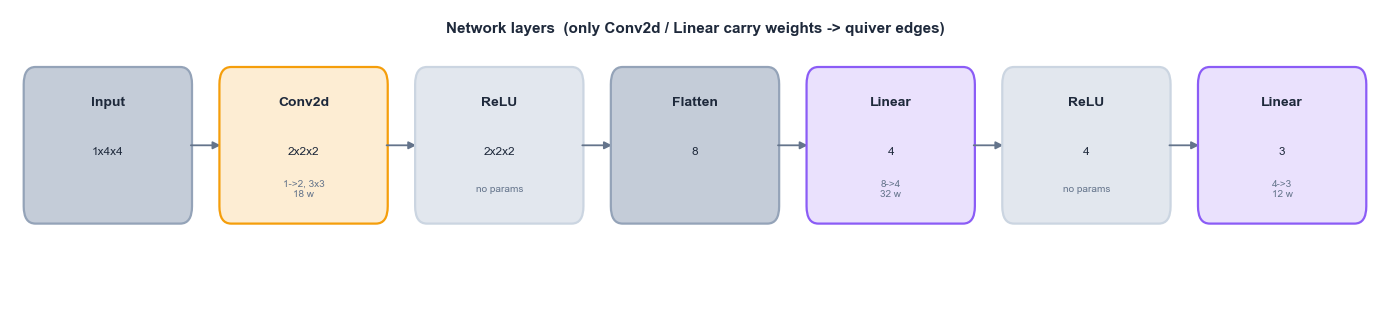

In [5]:
from notebook_viz import plot_network_layers
_ = plot_network_layers(net)
plt.show()

## A small, learnable dataset

Pruning is only meaningful on a network that has actually *learned* something,
so we use **separable** patterns (not random labels, which can't be fit):

- **class 0 — vertical bar** (columns 1–2 bright)
- **class 1 — horizontal bar** (rows 1–2 bright)
- **class 2 — diagonal** (main diagonal bright)

Each sample is its class template plus Gaussian noise (σ = 0.25). We standardize
with the training mean/std so pre-activations stay well away from zero (which
keeps the Eq. 5 denominator stable).

train: 600 samples,  test: 150 samples


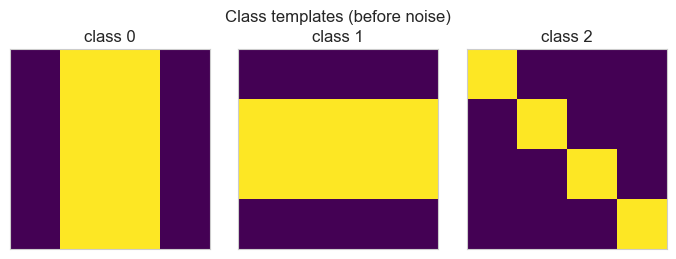

In [6]:
def make_image_dataset(n_per_class, noise=0.25, seed=0):
    rng = np.random.default_rng(seed)
    t0 = np.zeros((4, 4), np.float32); t0[:, 1:3] = 1.0   # vertical bar
    t1 = np.zeros((4, 4), np.float32); t1[1:3, :] = 1.0   # horizontal bar
    t2 = np.zeros((4, 4), np.float32); np.fill_diagonal(t2, 1.0)  # diagonal
    templates = [t0, t1, t2]
    X, y = [], []
    for c, t in enumerate(templates):
        for _ in range(n_per_class):
            X.append(t + rng.normal(0, noise, size=(4, 4)).astype(np.float32))
            y.append(c)
    X = np.stack(X)[:, None, :, :]           # (N, 1, 4, 4)
    return X.astype(np.float32), np.array(y), templates

Xtr, ytr, templates = make_image_dataset(200, seed=1)
Xte, yte, _         = make_image_dataset(50,  seed=2)

# Standardize using TRAIN statistics
mu, sd = Xtr.mean(), Xtr.std()
Xtr = (Xtr - mu) / sd
Xte = (Xte - mu) / sd

train_ds = TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr))
test_ds  = TensorDataset(torch.from_numpy(Xte), torch.from_numpy(yte))
trainloader = DataLoader(train_ds, batch_size=32, shuffle=True)
testloader  = DataLoader(test_ds,  batch_size=64, shuffle=False)
print(f"train: {len(train_ds)} samples,  test: {len(test_ds)} samples")

# Show one clean template per class
fig, ax = plt.subplots(1, 3, figsize=(7, 2.6))
for c, t in enumerate(templates):
    ax[c].imshow(t, cmap="viridis"); ax[c].set_title(f"class {c}")
    ax[c].set_xticks([]); ax[c].set_yticks([])
fig.suptitle("Class templates (before noise)")
plt.tight_layout(); plt.show()

### Train

We reuse `ExperimentRunner.train_network` / `evaluate_network` from
`experiments.py`. The net is tiny, so a few dozen epochs on CPU suffice to reach
high accuracy. We keep a deep copy of the trained weights to seed the pruning
baselines from an identical starting point.

In [7]:
import os

MODEL_PATH = "tinycnn_trained.pt"
if os.path.exists(MODEL_PATH):
    net.load_state_dict(torch.load(MODEL_PATH))
    print(f"Loaded trained model from {MODEL_PATH} (delete this file to force retraining).")
else:
    net, losses = runner.train_network(net, trainloader, epochs=40, lr=1e-2)
    torch.save(net.state_dict(), MODEL_PATH)
    print(f"Trained and saved model to {MODEL_PATH}.")

acc, _ = runner.evaluate_network(net, testloader)
print(f"Test accuracy: {acc:.1f}%")

trained_state = copy.deepcopy(net.state_dict())   # baseline starting point
assert acc >= 85.0, "network did not train well enough for a meaningful demo"

Loaded trained model from tinycnn_trained.pt (delete this file to force retraining).
Test accuracy: 100.0%


## Step 1 — Build the quiver

`QuiverRepresentation` turns the network into a quiver: **edges = coordinates**,
**vertices = one per parametric layer** (sized by output width). This is exactly
the construction in the figure at the top.

In [8]:
quiver = QuiverRepresentation(net)
print(f"#E (edges/coordinates): {len(quiver.edges)}")
print(f"#V (vertex entries):    {len(quiver.vertices)}  -> {quiver.vertices}")
print(f"moduli dimension #E-#V: {len(quiver.edges) - len(quiver.vertices)}")

# A few representative edges. Linear edge_info=(in_idx,out_idx); Conv edge_info=filter_idx
conv_edges = [e for e in quiver.edges if not isinstance(e[1], tuple)]
fc_edges   = [e for e in quiver.edges if isinstance(e[1], tuple)]
print("\nConv2d filter-edges:", conv_edges)
print("First 3 Linear edges:", fc_edges[:3])

assert len(quiver.edges) == 46 and len(quiver.vertices) == 3, "should match the figure"
print("\nMatches the visualization: #E=46, #V=3, moduli dim=43  ✓")

#E (edges/coordinates): 46
#V (vertex entries):    3  -> {'conv1_out': 2, 'fc1_out': 4, 'fc2_out': 3}
moduli dimension #E-#V: 43

Conv2d filter-edges: [(0, 0, 'conv1'), (1, 1, 'conv1')]
First 3 Linear edges: [(2, (0, 0), 'fc1'), (3, (0, 1), 'fc1'), (4, (0, 2), 'fc1')]

Matches the visualization: #E=46, #V=3, moduli dim=43  ✓


`plot_quiver` draws the quiver **derived from the `QuiverRepresentation` above**: each parametric layer becomes a column of vertices, Linear layers contribute one edge per weight, and the Conv2d layer uses the `filter = edge` convention (`out_channels` edges, fan-in collapsed). The dashed connectors are the flatten/reshape, which carries no weights.

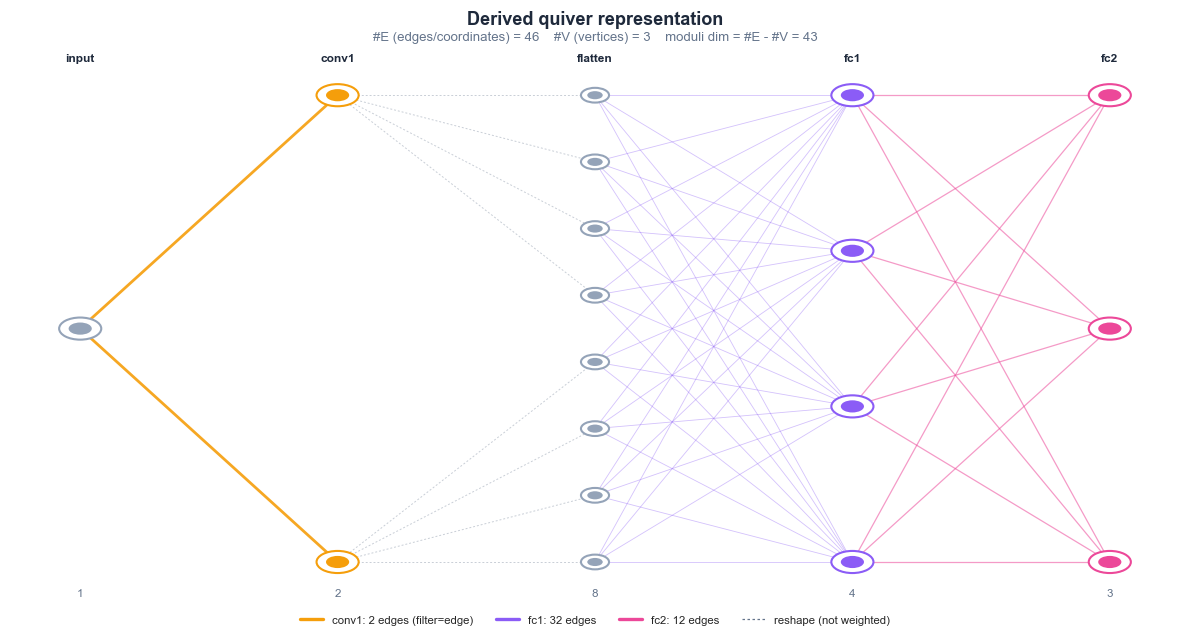

In [9]:
from notebook_viz import plot_quiver
_ = plot_quiver(quiver)
plt.show()

## Step 2 — The per-edge representation `W_x^f` (Eq. 5)

For one input `x`, `DataRepresentation.compute_representation` builds, for each
Linear layer, the **contribution-fraction** matrix

$$ (W_x^f)_{j,i} \;=\; \frac{W_{j,i}\, a_i}{\mathrm{preact}_j}, $$

i.e. how much input feature `i` contributes to output neuron `j`'s
pre-activation. **This varies per coordinate** (because `a_i` differs per input
index) — that is precisely what was missing before. Below is the `fc1` matrix
(4 outputs × 8 inputs) for a single test sample.

fc1 representation shape: (4, 8)


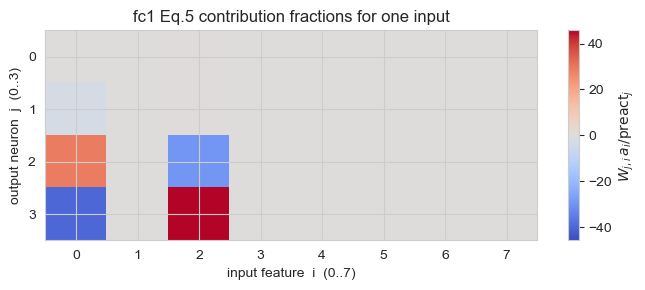

In [10]:
dr = DataRepresentation(net, device=DEVICE)
x0 = test_ds[0][0].unsqueeze(0)               # one sample, shape (1,1,4,4)
rep = dr.compute_representation(x0)
dr.cleanup()

M = rep["fc1"].cpu().numpy()                   # (4, 8)
print("fc1 representation shape:", M.shape)

vmax = np.abs(M).max()
plt.figure(figsize=(7, 3))
plt.imshow(M, cmap="coolwarm", vmin=-vmax, vmax=vmax, aspect="auto")
plt.colorbar(label=r"$W_{j,i}\,a_i/\mathrm{preact}_j$")
plt.xlabel("input feature  i  (0..7)"); plt.ylabel("output neuron  j  (0..3)")
plt.title("fc1 Eq.5 contribution fractions for one input")
plt.tight_layout(); plt.show()

### Tracing one input end-to-end

The heatmap above is one layer of a bigger picture. `plot_data_to_representation` traces a **single input** all the way through the network (top row: input image -> conv+ReLU -> flattened activations $a_i$ -> hidden -> logits -> predicted class), then shows exactly how those activations build the fc1 representation (bottom): the weight matrix $W[j,i]$ is scaled column-wise by the input activations $a_i$ and row-wise by the output pre-activations $\mathrm{preact}_j$ to give the contribution fractions $W_x^f[j,i] = W[j,i]\,a_i/\mathrm{preact}_j$. One coordinate feeding a healthy output neuron is highlighted with its scalar arithmetic.

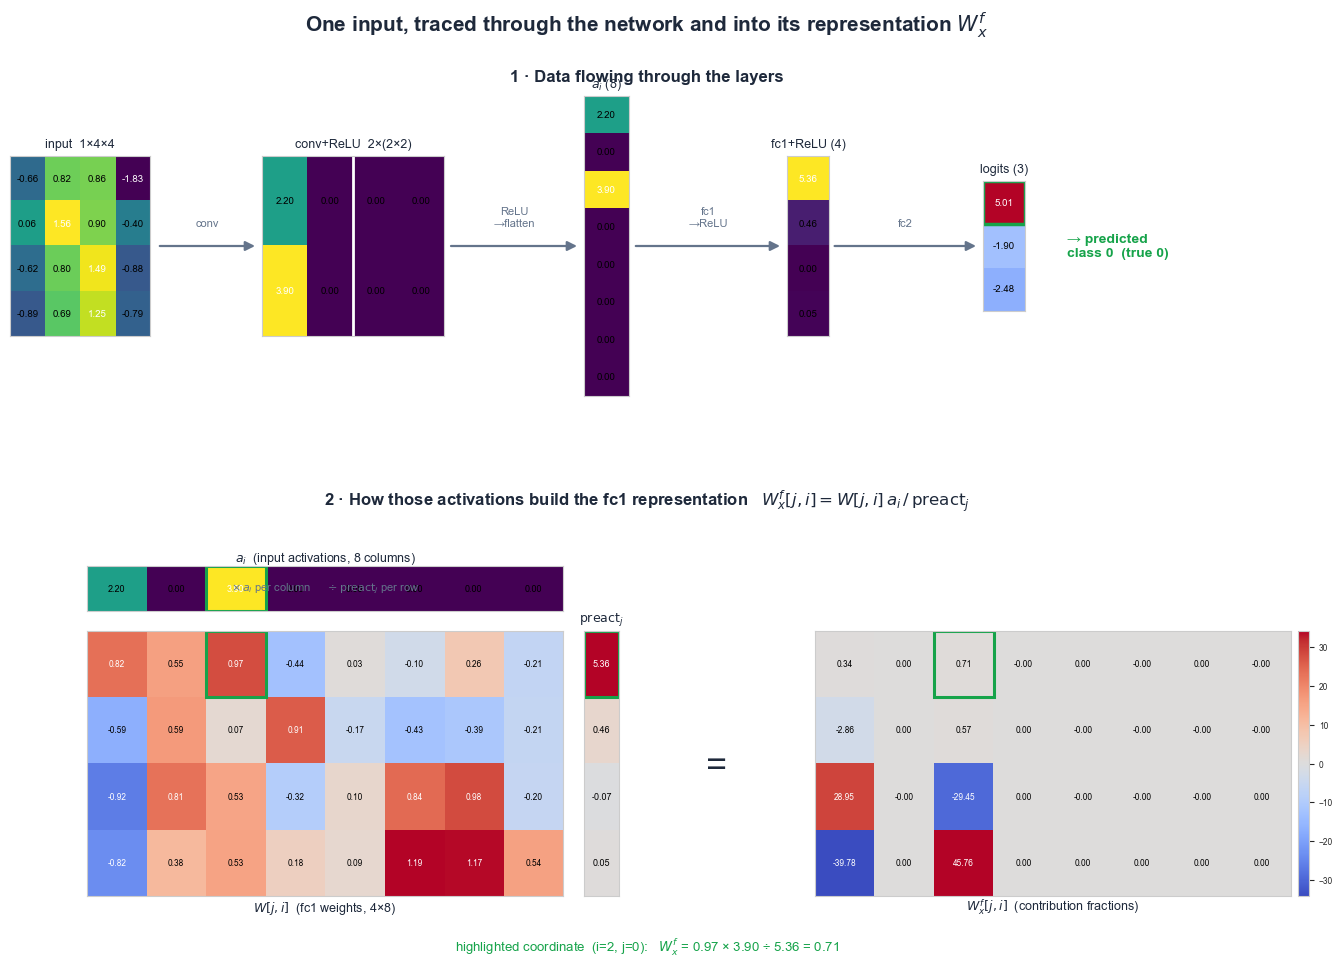

In [11]:
from notebook_viz import plot_data_to_representation
_ = plot_data_to_representation(net, x0, true_label=int(test_ds[0][1]))
plt.show()


## Step 2½ — Invariance: the central payoff (executable)

Section I.6 claimed $W_x^f$ is invariant under the ReLU gauge group, and that this is the
reason to prefer moduli coordinates over raw magnitudes. Here we **test it**.

Apply a function-preserving gauge transform — scale every weight *into* one hidden unit by
$c$ (and its bias), and every weight *out of* it by $1/c$ — then check:
1. the network function is unchanged;
2. $W_x^f$ is unchanged; and
3. the **moduli pruning decisions** are unchanged, whereas **magnitude pruning's
   decisions move**, because magnitude is not gauge-invariant.


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:00<00:00, 133.65it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:00<00:00, 142.68it/s]

(1) max |f(x) - f_gauge(x)| over test set = 1.91e-06   (~0 => same function)
(2) |W_x^f[fc1] - gauge|_max = 0.00e+00
(2) |W_x^f[fc2] - gauge|_max = 1.19e-07
(3) pruning-decision agreement before vs after gauge:  moduli=100.0%   magnitude=90.3%


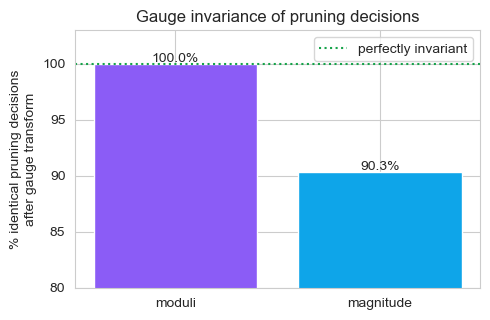

In [12]:
import contextlib, io

def gauge_rescale(model, unit=0, c=3.0):
    # Function-preserving ReLU gauge transform on one fc1 hidden unit.
    g = copy.deepcopy(model)
    with torch.no_grad():
        g.fc1.weight[unit] *= c          # arrows INTO the unit
        g.fc1.bias[unit]   *= c
        g.fc2.weight[:, unit] /= c       # arrows OUT of the unit (ReLU between)
    return g

net_gauge = gauge_rescale(net, unit=0, c=3.0)

# (1) function preserved
Xall = torch.from_numpy(Xte)
with torch.no_grad():
    fdiff = (net(Xall) - net_gauge(Xall)).abs().max().item()
print(f"(1) max |f(x) - f_gauge(x)| over test set = {fdiff:.2e}   (~0 => same function)")

# (2) W_x^f invariant
def fc_rep(model, layer):
    d = DataRepresentation(model, device=DEVICE); r = d.compute_representation(x0); d.cleanup()
    return r[layer].detach().cpu().numpy()
for L in ["fc1", "fc2"]:
    print(f"(2) |W_x^f[{L}] - gauge|_max = {np.abs(fc_rep(net, L) - fc_rep(net_gauge, L)).max():.2e}")

# (3) pruning-decision invariance
# Deterministic, full-coverage loader so the ONLY variable is the gauge transform
# (trainloader is shuffled and subsampled, which would otherwise add margin noise).
eval_loader = DataLoader(train_ds, batch_size=64, shuffle=False)

def decisions(model, method, ratio=0.5):
    m = copy.deepcopy(model)
    with contextlib.redirect_stdout(io.StringIO()):
        if method == "moduli":
            an = ModuliSpaceAnalyzer(model, device=DEVICE); an.analyze_dataset(eval_loader, max_samples=len(train_ds))
            _, masks = ModuliSpacePruner(m, an).prune(ratio, "combined")
        else:
            _, masks = BasePruningMethods.magnitude_pruning(m, ratio)
    return {k: (v == 0).cpu().numpy() for k, v in masks.items()}

def agreement(a, b):
    tot = sum(x.size for x in a.values()); same = sum((a[k] == b[k]).sum() for k in a)
    return 100.0 * same / tot

ag_mod = agreement(decisions(net, "moduli"),    decisions(net_gauge, "moduli"))
ag_mag = agreement(decisions(net, "magnitude"), decisions(net_gauge, "magnitude"))
print(f"(3) pruning-decision agreement before vs after gauge:  moduli={ag_mod:.1f}%   magnitude={ag_mag:.1f}%")

plt.figure(figsize=(5, 3.3))
plt.bar(["moduli", "magnitude"], [ag_mod, ag_mag], color=["#8b5cf6", "#0ea5e9"])
plt.axhline(100, ls=":", color="#16a34a", label="perfectly invariant")
for i, v in enumerate([ag_mod, ag_mag]): plt.text(i, v + 0.2, f"{v:.1f}%", ha="center")
plt.ylim(80, 103); plt.ylabel("% identical pruning decisions\nafter gauge transform")
plt.title("Gauge invariance of pruning decisions"); plt.legend(); plt.tight_layout(); plt.show()


**What you should see.** The function is preserved to floating-point ($\sim10^{-6}$),
$W_x^f$ is invariant (fc1 *exactly*; fc2 to floating-point), and moduli pruning makes the
**same** decisions before and after the gauge transform (100%), while magnitude pruning
does **not** (it changes for the rescaled unit's weights). This is the theory's central
claim, made concrete: moduli coordinates are properties of the *function*, not of the
*parameterization*.


## Step 3 — Analyze coordinate statistics over the dataset

`ModuliSpaceAnalyzer.analyze_dataset` collects each coordinate's value across
many inputs and computes three metrics — **usage rate** (how often the
coordinate is active), **variance** (how much its Eq. 5 contribution swings
across inputs), and **information content** (entropy of its on/off pattern) —
combined into an **importance score** `usage · √variance · (1 + info)`.

The histograms below now show a genuine *spread* of values across coordinates.
(Before the fix every layer collapsed to a single spike.)

> Because ReLU zeros some activations, `usage_rate` genuinely **varies** here
> (it is *not* ~1 for every coordinate), so all three metrics carry signal. The
> resulting importance is concentrated in a small number of high-usage,
> high-variance coordinates — note the long right tail in the importance panel.

Analyzing moduli space coordinates...


  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 267.57it/s]

analyzed coordinates: 46
distinct importance values: 46 of 46


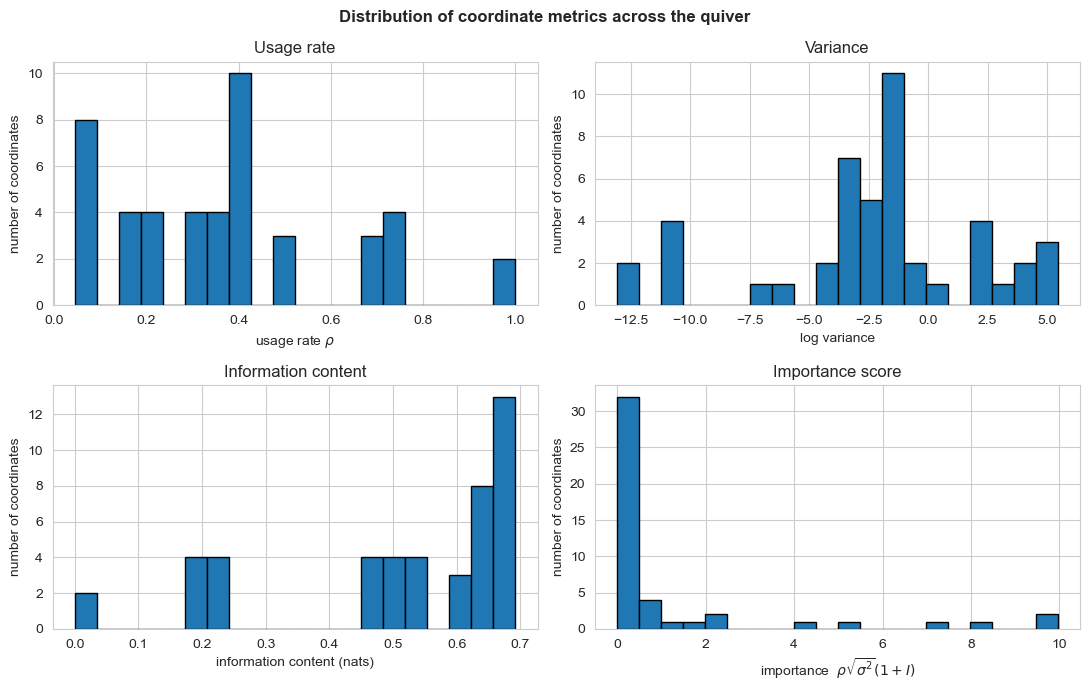

In [13]:
analyzer = ModuliSpaceAnalyzer(net, device=DEVICE)
analyzer.analyze_dataset(trainloader, max_samples=400)
coords = analyzer.coordinates
print(f"analyzed coordinates: {len(coords)}")

import numpy as np
usage = np.array([c.usage_rate for c in coords])
var   = np.array([c.variance for c in coords])
info  = np.array([c.information_content for c in coords])
imp   = np.array([c.importance_score for c in coords])
print(f"distinct importance values: {len(np.unique(np.round(imp, 8)))} of {len(imp)}")

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    (ax[0,0], usage,                  r"usage rate $\rho$",            "Usage rate"),
    (ax[0,1], np.log(var + 1e-12),    "log variance",                  "Variance"),
    (ax[1,0], info,                   "information content (nats)",    "Information content"),
    (ax[1,1], imp,                    r"importance  $\rho\sqrt{\sigma^2}(1+I)$", "Importance score"),
]
for a, data, xlabel, title in panels:
    a.hist(data, bins=20, edgecolor="k")
    a.set_title(title)
    a.set_xlabel(xlabel)
    a.set_ylabel("number of coordinates")
fig.suptitle("Distribution of coordinate metrics across the quiver", fontweight="bold")
plt.tight_layout(); plt.show()

## Step 4 — From coordinates to weights

The lowest-importance coordinates are the prune candidates. Each maps back to a
specific weight: Linear edge `(i, j) → weight[j, i]`, Conv filter `i → weight[i]`.
We rebuild the `fc1` importance grid (4×8) so we can *see* which weights are
considered least important before pruning.

Lowest-importance coordinates (prune first):
  edge  18  fc1    info=(4, 0)   importance=1.073e-04
  edge  32  fc1    info=(7, 2)   importance=1.154e-04
  edge  30  fc1    info=(7, 0)   importance=2.453e-04
  edge  33  fc1    info=(7, 3)   importance=2.532e-04
  edge  20  fc1    info=(4, 2)   importance=2.874e-04
  edge  21  fc1    info=(4, 3)   importance=4.168e-04
  edge  31  fc1    info=(7, 1)   importance=2.202e-03
  edge  19  fc1    info=(4, 1)   importance=8.068e-03


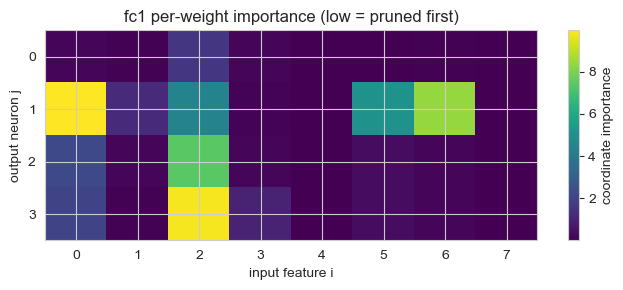

In [14]:
prunable = analyzer.get_prunable_coordinates(0.5, strategy="combined")
edge_lookup = {e_idx: (l_name, e_info) for e_idx, e_info, l_name in quiver.edges}
print("Lowest-importance coordinates (prune first):")
for c in prunable[:8]:
    lname, einfo = edge_lookup[c.edge_idx]
    print(f"  edge {c.edge_idx:>3}  {lname:<6} info={str(einfo):<8} importance={c.importance_score:.3e}")

# fc1 importance grid (4x8)
imp_grid = np.full((4, 8), np.nan)
for e_idx, e_info, l_name in quiver.edges:
    if l_name == "fc1":
        i_in, j_out = e_info
        imp_grid[j_out, i_in] = analyzer.coordinate_stats[e_idx].importance_score

plt.figure(figsize=(7, 3))
plt.imshow(imp_grid, cmap="viridis", aspect="auto")
plt.colorbar(label="coordinate importance")
plt.xlabel("input feature i"); plt.ylabel("output neuron j")
plt.title("fc1 per-weight importance (low = pruned first)")
plt.tight_layout(); plt.show()

## Step 5 — Prune

`ModuliSpacePruner.prune` maps every weight to its coordinate's importance, then
globally zeros the lowest-importance weights up to the target sparsity (so the
ratio is hit exactly while the *ranking* comes from the moduli coordinates).

  Total weights: 62
  Target pruned: 31 (50%)  [strategy=combined]
  Actually pruned: 31 weights (50.0%)

achieved sparsity: 50.0%  (target 50%)


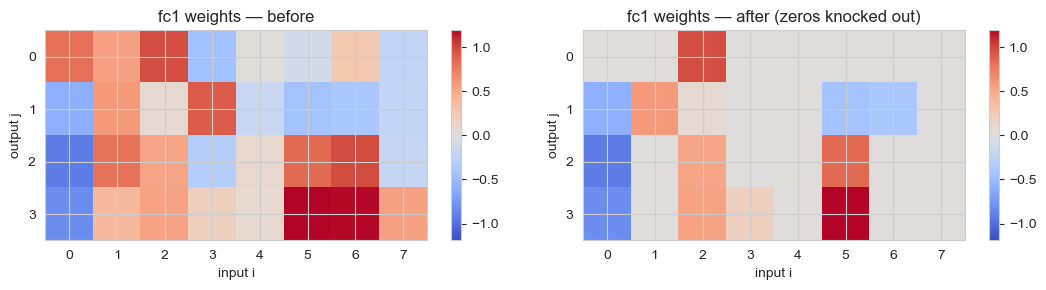

In [15]:
net_moduli = TinyCNN(); net_moduli.load_state_dict(trained_state)
pruner = ModuliSpacePruner(net_moduli, analyzer)

fc1_before = net_moduli.fc1.weight.data.clone().cpu().numpy()
net_moduli, masks = pruner.prune(pruning_ratio=0.5, strategy="combined")
fc1_after = net_moduli.fc1.weight.data.clone().cpu().numpy()

sparsity = runner.compute_sparsity(net_moduli)
print(f"\nachieved sparsity: {sparsity*100:.1f}%  (target 50%)")
assert abs(sparsity - 0.5) < 0.05

vmax = np.abs(fc1_before).max()
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a, W, ttl in [(ax[0], fc1_before, "fc1 weights — before"),
                  (ax[1], fc1_after,  "fc1 weights — after (zeros knocked out)")]:
    im = a.imshow(W, cmap="coolwarm", vmin=-vmax, vmax=vmax, aspect="auto")
    a.set_title(ttl); a.set_xlabel("input i"); a.set_ylabel("output j")
    fig.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

## Step 6 — Does it still work? Baselines at 50% sparsity

We compare the moduli-pruned network against **magnitude** and **random**
pruning, each started from the *same* trained weights.

  Total weights: 62
  Target pruned: 31 (50%)  [strategy=combined]
  Actually pruned: 31 weights (50.0%)
moduli     acc= 72.0%  sparsity=50.0%
magnitude  acc= 85.3%  sparsity=50.0%
random     acc= 66.0%  sparsity=43.5%


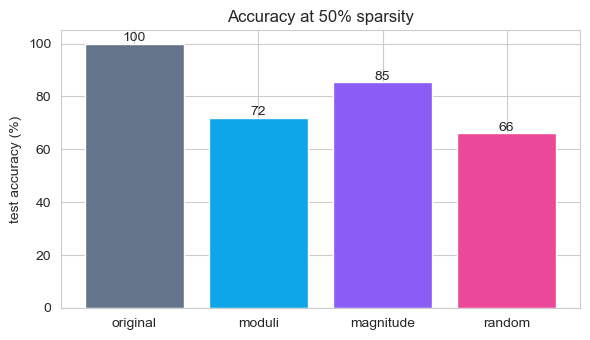

In [16]:
def prune_and_eval(method, ratio):
    m = TinyCNN(); m.load_state_dict(trained_state)
    if method == "moduli":
        ModuliSpacePruner(m, analyzer).prune(pruning_ratio=ratio, strategy="combined")
    elif method == "magnitude":
        BasePruningMethods.magnitude_pruning(m, pruning_ratio=ratio)
    elif method == "random":
        BasePruningMethods.random_pruning(m, pruning_ratio=ratio)
    acc, _ = runner.evaluate_network(m, testloader)
    return acc, runner.compute_sparsity(m)

orig_acc, _ = runner.evaluate_network(net, testloader)
results = {"original": orig_acc}
for method in ["moduli", "magnitude", "random"]:
    a, s = prune_and_eval(method, 0.5)
    results[method] = a
    print(f"{method:<10} acc={a:5.1f}%  sparsity={s*100:4.1f}%")

plt.figure(figsize=(6, 3.5))
names = list(results); vals = [results[n] for n in names]
colors = ["#64748b", "#0ea5e9", "#8b5cf6", "#ec4899"]
plt.bar(names, vals, color=colors[:len(names)])
plt.ylabel("test accuracy (%)"); plt.title("Accuracy at 50% sparsity")
for i, v in enumerate(vals): plt.text(i, v + 1, f"{v:.0f}", ha="center")
plt.ylim(0, 105); plt.tight_layout(); plt.show()

## Step 7 — Accuracy vs sparsity sweep

How gracefully does each method degrade as we prune more aggressively?

  Total weights: 62
  Target pruned: 6 (10%)  [strategy=combined]
  Actually pruned: 6 weights (9.7%)
  Total weights: 62
  Target pruned: 12 (20%)  [strategy=combined]
  Actually pruned: 12 weights (19.4%)
  Total weights: 62
  Target pruned: 18 (30%)  [strategy=combined]
  Actually pruned: 18 weights (29.0%)
  Total weights: 62
  Target pruned: 24 (40%)  [strategy=combined]
  Actually pruned: 24 weights (38.7%)
  Total weights: 62
  Target pruned: 31 (50%)  [strategy=combined]
  Actually pruned: 31 weights (50.0%)
  Total weights: 62
  Target pruned: 37 (60%)  [strategy=combined]
  Actually pruned: 37 weights (59.7%)
  Total weights: 62
  Target pruned: 43 (70%)  [strategy=combined]
  Actually pruned: 43 weights (69.4%)
  Total weights: 62
  Target pruned: 49 (80%)  [strategy=combined]
  Actually pruned: 49 weights (79.0%)
  Total weights: 62
  Target pruned: 55 (90%)  [strategy=combined]
  Actually pruned: 55 weights (88.7%)


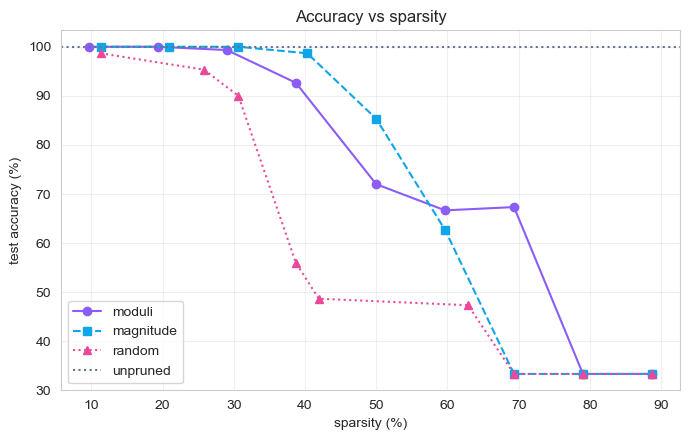

In [17]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
curves = {m: [] for m in ["moduli", "magnitude", "random"]}
spars  = {m: [] for m in curves}
for r in ratios:
    for m in curves:
        a, s = prune_and_eval(m, r)
        curves[m].append(a); spars[m].append(s * 100)

plt.figure(figsize=(7, 4.5))
style = {"moduli": ("#8b5cf6", "o-"), "magnitude": ("#0ea5e9", "s--"), "random": ("#ec4899", "^:")}
for m in curves:
    c, ls = style[m]
    plt.plot(spars[m], curves[m], ls, color=c, label=m)
plt.axhline(orig_acc, color="#64748b", ls=":", label="unpruned")
plt.xlabel("sparsity (%)"); plt.ylabel("test accuracy (%)")
plt.title("Accuracy vs sparsity"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Reading the sweep (single seed — interpret with caution)

This is **one** trained model and **one** random-pruning draw, so treat the exact
ordering as anecdotal — random pruning especially is high-variance. The honest version
is the **multi-seed sweep with error bars** in Step 7½ below; rely on that for any claim.

What is robust even here: all structured criteria (moduli / magnitude / structured) sit
far above **random**, and at low sparsity everything is near-perfect. Where the methods
sit *relative to each other* is exactly what a single seed cannot tell you — hence the
next section.


## Step 7½ — Rigorous evaluation: many seeds, with error bars

The sweep above is a *single* trained model and a *single* random-pruning draw — fine for
intuition, useless for a claim. Random pruning is high-variance, and different
initializations land in different basins. To make any statement like "moduli degrades
more gracefully at high sparsity," we need **mean ± std over several seeds**.

The cell retrains $K$ models from scratch (fast on this toy), reruns the full sweep for
each method including the **structured** baseline, and plots mean curves with std bands.


  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 274.29it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 275.56it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 271.15it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 274.07it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

 68%|██████▊   | 13/19 [00:00<00:00, 274.92it/s]

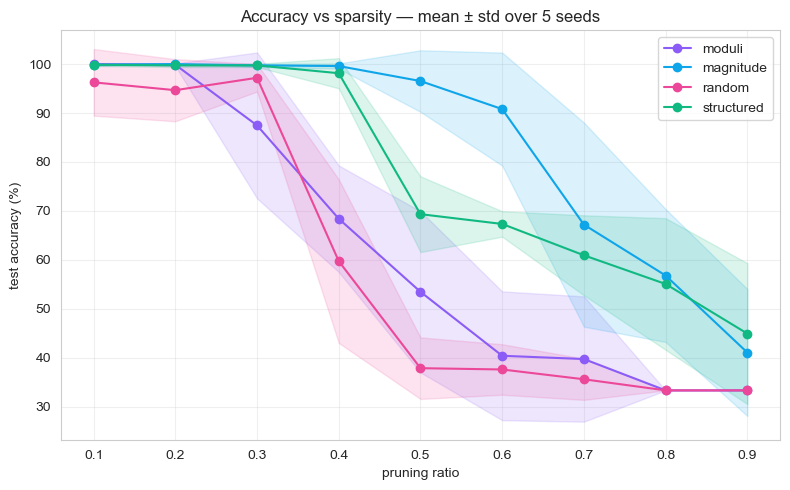

mean accuracy by method and ratio:
ratio    0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9
moduli      100   100    87    68    53    40    40    33    33
magnitude   100   100   100   100    97    91    67    57    41
random       96    95    97    60    38    38    36    33    33
structured  100   100   100    98    69    67    61    55    45


In [18]:
from collections import defaultdict
import contextlib, io

SEEDS   = [0, 1, 2, 3, 4]
RATIOS  = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
METHODS = ["moduli", "magnitude", "random", "structured"]
acc = {m: np.zeros((len(SEEDS), len(RATIOS))) for m in METHODS}

for si, seed in enumerate(SEEDS):
    torch.manual_seed(seed)
    base = TinyCNN()
    with contextlib.redirect_stderr(io.StringIO()):              # hide tqdm bars
        base, _ = runner.train_network(base, trainloader, epochs=30, lr=1e-2)
    st = copy.deepcopy(base.state_dict())
    with contextlib.redirect_stdout(io.StringIO()):
        an = ModuliSpaceAnalyzer(base, device=DEVICE); an.analyze_dataset(trainloader, max_samples=400)
    for ri, r in enumerate(RATIOS):
        for meth in METHODS:
            mm = TinyCNN(); mm.load_state_dict(st)
            with contextlib.redirect_stdout(io.StringIO()):
                if   meth == "moduli":     ModuliSpacePruner(mm, an).prune(r, "combined")
                elif meth == "magnitude":  BasePruningMethods.magnitude_pruning(mm, r)
                elif meth == "structured": BasePruningMethods.structured_pruning(mm, r)
                else:
                    torch.manual_seed(1000 * seed + ri); BasePruningMethods.random_pruning(mm, r)
            a, _ = runner.evaluate_network(mm, testloader); acc[meth][si, ri] = a

plt.figure(figsize=(8, 5))
colors = {"moduli": "#8b5cf6", "magnitude": "#0ea5e9", "random": "#ec4899", "structured": "#10b981"}
for meth in METHODS:
    mean, std = acc[meth].mean(0), acc[meth].std(0)
    plt.plot(RATIOS, mean, "o-", color=colors[meth], label=meth)
    plt.fill_between(RATIOS, mean - std, mean + std, color=colors[meth], alpha=0.15)
plt.xlabel("pruning ratio"); plt.ylabel("test accuracy (%)")
plt.title(f"Accuracy vs sparsity — mean ± std over {len(SEEDS)} seeds")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("mean accuracy by method and ratio:")
print("ratio   " + "  ".join(f"{r:>4.1f}" for r in RATIOS))
for meth in METHODS:
    print(f"{meth:<10} " + "  ".join(f"{v:4.0f}" for v in acc[meth].mean(0)))

**What the seeds actually say (read the bands, not the lines).** On this 4×4 toy, magnitude and structured pruning generally **match or beat** moduli pruning across the sparsity range, with moduli competitive only at low sparsity; all three sit far above random. In other words, moduli pruning is **not** a free accuracy win here — its demonstrated advantage is **invariance** (Step 2½), not the accuracy–sparsity curve on this dataset.

That is an honest and useful result for you: it sharpens the central open question — *can a principled, geometry-derived importance measure (Part III) turn the invariance property into an accuracy advantage?* This toy is the harness to test that; real conclusions need the CIFAR/ResNet-18 scripts and many seeds. Where bands overlap, treat any ordering as noise.


## Step 8 — Prune, then fine-tune (the Lottery-Ticket protocol)

Pruning is rarely the last step: you prune, then **fine-tune** with the pruned weights
held at zero, and report the *recovered* accuracy. The cell below prunes at an aggressive
ratio (where one-shot pruning clearly hurts) and fine-tunes with the mask re-applied after
every optimizer step, so sparsity is preserved.


In [19]:
def masked_finetune(model, masks, epochs=15, lr=5e-3):
    # Fine-tune while keeping pruned weights pinned to zero (re-apply mask each step).
    model = copy.deepcopy(model); model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.CrossEntropyLoss()
    name2mod = dict(model.named_modules())
    for _ in range(epochs):
        for xb, yb in trainloader:
            opt.zero_grad(); lossf(model(xb), yb).backward(); opt.step()
            with torch.no_grad():
                for n, msk in masks.items():
                    name2mod[n].weight.data *= msk
    model.eval(); return model

R = 0.7
mp = TinyCNN(); mp.load_state_dict(trained_state)
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    _, masks = ModuliSpacePruner(mp, analyzer).prune(R, "combined")
acc_pruned, _ = runner.evaluate_network(mp, testloader)
mp_ft = masked_finetune(mp, masks, epochs=15)
acc_ft, _ = runner.evaluate_network(mp_ft, testloader)
print(f"moduli @ {int(R*100)}% sparsity:  one-shot {acc_pruned:.1f}%  ->  fine-tuned {acc_ft:.1f}%"
      f"   (sparsity held at {runner.compute_sparsity(mp_ft)*100:.0f}%)")

moduli @ 70% sparsity:  one-shot 67.3%  ->  fine-tuned 99.3%   (sparsity held at 69%)



The recovered number is the fair one to report for any pruning method. A natural research
extension (Part III) is to run the *prune→fine-tune* loop iteratively and ask whether
moduli-selected masks are better "winning tickets" than magnitude-selected ones.



# Part III — Rigor, limitations, and research directions



## Where this implementation diverges from the theory

Read this before extending the code. Each item is a place the implementation makes a
simplification or differs from Armenta–Jodoin; several are good first projects to fix.

1. **Moduli dimension uses #layers, not #hidden vertices.**
   `analyzer.moduli_dimension` returns `#E - len(vertices)`, and `vertices` has one entry
   per parametric *layer*. For our CNN that is $46-3=\mathbf{43}$, whereas the paper's
   $\#E-\#\tilde V$ with hidden *vertices* (2 conv channels + 4 fc1 units) is
   $46-6=\mathbf{40}$. The "43" in Step 1 is therefore **not** the paper's moduli
   dimension. *Fix:* sum hidden-vertex widths instead of counting layers.

2. **Conv "filter = edge" + edge-count asymmetry.** A `Linear` layer emits `in×out`
   arrows (one per scalar weight), but a `Conv2d` emits only `out_channels` (one per
   filter), with the input fan-in and the $k{\times}k$ kernel collapsed. So a "coordinate"
   means different things in different layers, and conv layers are massively
   under-represented (2 of 46 here). *Fix:* emit `in×out` filter-edges, or weight each
   filter-edge by its kernel block, and compute $W_x^f$ per filter.

3. **Bias is inside the denominator.** The code's pre-activation is $Wa+b$, but Eq. 5's
   normalization is the pure incoming-edge sum $\sum_i W_{ji}a_i$ (no bias). (Numerically
   here, e.g. neuron 1: $0.46$ with bias vs $-1.05$ without.) Invariance under the *scaling
   we tested* still holds because we scaled the bias too, but this differs from the literal
   formula. *Fix:* model bias as an arrow from a constant "1" vertex (then it is a genuine
   edge and the formula is exact).

4. **Doc vs. code on $\zeta$.** `education/02_moduli_space.md` writes the denominator over
   $\zeta_{s(\varepsilon)}$ (source), but the paper defines $\zeta_v$ as edges into the
   **target** and the code normalizes by the target's pre-activation. The code matches the
   paper; the written subscript in that doc is a typo. Trust the code here.

5. **The importance score is a heuristic, not from the paper.**
   $\rho\cdot\sqrt{\sigma^2}\cdot(1+I)$ is this repo's invention. On a trained net it is
   dominated by usage and variance. Deriving a *principled* importance from moduli geometry
   is the most interesting open problem (below).

6. **`prune()` makes engineering choices.** It assigns each weight its coordinate's
   importance and globally zeros the lowest (to hit the exact target sparsity), breaking
   intra-filter ties by magnitude. Reasonable, but not dictated by the theory.



## Open problems / research agenda

Concrete next steps, roughly in increasing order of ambition:

1. **Fix the bookkeeping (warm-up).** Implement the correct $\#\tilde V$ moduli dimension
   (#1 above) and add a test; fold bias in as a constant-vertex edge (#3).
2. **Faithful convolutions.** Replace filter-as-edge with per-weight (or per-filter-block)
   conv edges and a per-filter $W_x^f$ (#2). Re-run the ResNet-18/CIFAR experiments and see
   whether conv coordinates then carry real signal.
3. **A principled importance measure.** Replace the usage·var·info heuristic with something
   derived from the moduli geometry — e.g. a coordinate's contribution to the **basis-path
   norm** (Zheng et al.), distance to the nearest singular stratum, or a Fisher-information
   weighting on $\mathcal M$. Hypothesis: a geometry-derived score beats magnitude at
   matched sparsity *after fine-tuning*.
4. **Invariance audit at scale.** Generalize the Step 2½ test: sample random gauge
   transforms (and permutations) on a deep net and quantify the invariance of each
   pruning method's *masks* and *post-fine-tune accuracy*. Does the invariance advantage
   translate into a generalization advantage?
5. **Lottery tickets.** Run iterative prune→fine-tune with moduli vs. magnitude masks;
   compare "winning ticket" quality and stability across seeds.
6. **Generalization theory.** Relate coordinate importance / moduli position to
   generalization bounds (basis-path norm, PAC-Bayes over $\mathcal M$).
7. **Scale & architectures.** Extend `_extract_edges` to attention/residual/normalization
   layers and test on a small transformer.

Each is framed as a hypothesis + an experiment you can run with the existing harness.



## Glossary

| Term | Meaning |
|---|---|
| **Quiver** $Q=(Q_0,Q_1,s,t)$ | Directed multigraph: vertices, arrows, source/target maps. |
| **Network quiver** | The quiver whose vertices are neurons/channels and arrows are weighted connections. |
| **Representation** $W$ | Vector space per vertex + linear map per arrow; for a network, the weights. |
| **Dimension vector** $\mathbf d$ | The tuple of vertex dimensions. |
| **Thin** representation | All vertex spaces are 1-dimensional (each arrow map is a scalar). |
| **Activation** $a(W,f)_v(x)$ | Neuron $v$'s output on input $x$ (Def. 4.7). |
| $\zeta_v$ | Arrows with **target** $v$ (the incoming edges); their weighted sum is the pre-activation. |
| **Gauge group** $\tilde G$ | $\prod_{v\in\tilde V}\mathbb C^*$ (or $\mathbb R_{>0}$): one change-of-basis scalar per hidden vertex. |
| **Orbit / isomorphism class** | All weight settings related by $\tilde G$ — same network function. |
| **Moduli space** $\mathcal M$ | $\mathrm{Rep}(Q,\mathbf d)/\!/\tilde G$; points = isomorphism classes; $\dim=\#E-\#\tilde V$. |
| **Data representation** $W_x^f$ | The thin representation induced by a forward pass; the normalized contribution fractions. |
| **Coordinate** | One entry of $W_x^f$, i.e. one arrow/edge of the quiver. |
| **Usage / variance / information** | Per-coordinate statistics over the dataset, combined into the importance score. |
| **Basis path** | A product of normalized coordinates along a path; basis-path norm controls ReLU-net capacity. |



## Summary & where to go next

- A neural network **is** a representation of its network quiver; the weights live in
  $\mathrm{Rep}(Q,\mathbf d)\cong\mathbb R^{\#E}$.
- The **gauge group** $\tilde G$ (ReLU rescalings + permutations) identifies networks with
  the same function; the **moduli space** $\mathcal M=\mathrm{Rep}/\!/\tilde G$ is the true
  parameter space, of dimension $\#E-\#\tilde V$.
- The **data representation** $W_x^f$ gives parameterization-independent coordinates; its
  defining normalization is exactly what makes it **gauge-invariant** — verified
  numerically in Step 2½ (moduli pruning's decisions are invariant; magnitude pruning's are
  not).
- **Coordinate statistics → importance → pruning** hits the target sparsity exactly and is
  *data-aware*. But on this toy, the **multi-seed** sweep shows magnitude/structured
  generally match or beat moduli (moduli is competitive only at low sparsity); all beat
  random. Moduli's demonstrated advantage here is **invariance**, not the accuracy curve —
  turning that into an accuracy win is the open problem.
- **The implementation diverges from the theory** in named, fixable ways (moduli-dimension
  count, conv filter-as-edge, bias-in-denominator, heuristic importance). These are your
  starting projects.

**Next:** pick an item from the research agenda; scale up with
`experiments_resnet18.py`; and use `analysis.py` (`ModuliSpaceVisualizer`) — its PCA/t-SNE
embeddings of $W_x^f$ are now meaningful since the representation is genuinely per-edge.
Read arXiv:2007.12213 Sections 3–6 alongside Part I.
